# 09 · SigLIP ViT-B/16: search by what is in the photograph

**What it is.** SigLIP (Zhai et al., ICCV 2023, `timm/ViT-B-16-SigLIP`, 812 MB, Apache-2.0) embeds a photograph and a text query into the same space; the cosine similarity ranks photographs for a sentence such as "a dark photo taken at night". Photographs are indexed once (one 768-number vector each) and a query is a matrix product. English queries only.

**How it is scored.** There is no hand-labelled caption set, so labels come from *other measurements of the same photographs*: "contains a person" = YuNet found a face, "dark" = measured mean luminance < 60, "bright" = > 130. Each query is scored with **ROC-AUC, average precision, precision@10** over every indexed photograph, and the **minimum-score floor** the application uses (`SEMANTIC_SEARCH_MIN_SCORE`) is chosen from a precision/recall sweep.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


In [2]:
from search.models import ImageEmbedding
from search.semantic import service as svc
from search.semantic.embedders import decode_vectors
from validation.models import FaceValidationResult
from quality_control.models import ImageQualityDecision

embedder = svc.get_embedder(); embedder.ready()
rows = list(ImageEmbedding.objects.filter(model_checksum=embedder.checksum, image__in=svc.eligible_images()).values_list("image_id", "vector", "dimension"))
ids = [r[0] for r in rows]; matrix = decode_vectors([r[1] for r in rows], rows[0][2])
faces = dict(FaceValidationResult.objects.filter(image_id__in=ids).values_list("image_id", "face_count"))
lum = {}
for image_id, m in ImageQualityDecision.objects.filter(image_id__in=ids).values_list("image_id", "measurements"):
    if isinstance(m, dict) and m.get("mean_luminance") is not None: lum[image_id] = float(m["mean_luminance"])
print(len(ids), "indexed photographs;", len(faces), "with a face count;", len(lum), "with a measured luminance")
queries = [("a photo of a person", "contains a person (YuNet found a face)", lambda i: faces.get(i, 0) > 0, [i for i in ids if i in faces]),
           ("a photo of a landscape, a building or an object with no people", "no person", lambda i: faces.get(i, 1) == 0, [i for i in ids if i in faces]),
           ("a dark photo taken at night", "dark (mean luminance < 60)", lambda i: lum[i] < 60, [i for i in ids if i in lum]),
           ("a bright photo taken in daylight", "bright (mean luminance > 130)", lambda i: lum[i] > 130, [i for i in ids if i in lum])]
index = {pk: n for n, pk in enumerate(ids)}
results = []
for text, label_name, rule, pool in queries:
    q = embedder.embed_texts([text])[0]; scores = np.array([matrix[index[i]] @ q for i in pool]); labels = np.array([rule(i) for i in pool], int)
    auc = float((scores[labels == 1][:, None] > scores[labels == 0][None, :]).mean()) if labels.min() == 0 and labels.max() == 1 else float("nan")
    order = np.argsort(-scores); p10 = float(labels[order][:10].mean())
    results.append({"query": text[:44], "label": label_name, "positives": int(labels.sum()), "of": len(pool), "roc_auc": round(auc, 3), "avg_precision": round(average_precision(labels, scores), 3), "precision@10": round(p10, 2), "_scores": scores, "_labels": labels})
table([{k: v for k, v in r.items() if not k.startswith("_")} for r in results])

2026-11-24 07:19:52,415 INFO search.semantic.embedders Search-by-meaning model ViT-B-16-SigLIP loaded on mps (dimension 768).


274 indexed photographs; 272 with a face count; 272 with a measured luminance
query                                         label                                   positives  of   roc_auc  avg_precision  precision@10
--------------------------------------------  --------------------------------------  ---------  ---  -------  -------------  ------------
a photo of a person                           contains a person (YuNet found a face)  223        272  0.609    0.856          0.8         
a photo of a landscape, a building or an obj  no person                               49         272  0.75     0.482          0.9         
a dark photo taken at night                   dark (mean luminance < 60)              52         272  0.893    0.729          0.9         
a bright photo taken in daylight              bright (mean luminance > 130)           85         272  0.439    0.279          0.0         


at the application floor 0.06
query                                         returned  precision  recall
--------------------------------------------  --------  ---------  ------
a photo of a person                           140       0.843      0.529 
a photo of a landscape, a building or an obj  6         1.0        0.122 
a dark photo taken at night                   43        0.721      0.596 
a bright photo taken in daylight              98        0.214      0.247 


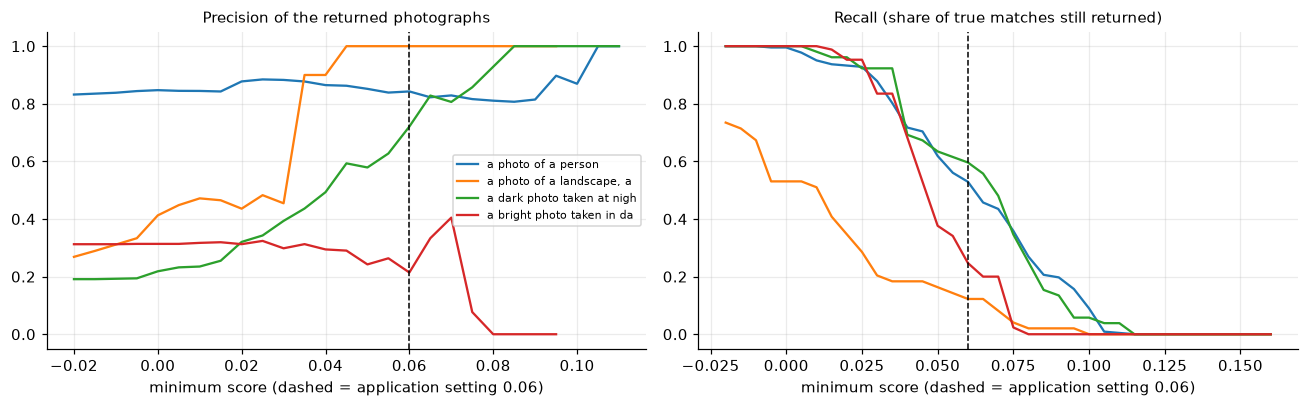

In [3]:
floors = np.linspace(-0.02, 0.16, 37)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for r in results:
    prec = [r["_labels"][r["_scores"] >= f].mean() if (r["_scores"] >= f).any() else np.nan for f in floors]
    rec = [(r["_scores"] >= f)[r["_labels"] == 1].mean() for f in floors]
    ax[0].plot(floors, prec, label=r["query"][:26]); ax[1].plot(floors, rec)
for a, t in zip(ax, ("Precision of the returned photographs", "Recall (share of true matches still returned)")):
    a.axvline(settings.SEMANTIC_SEARCH_MIN_SCORE, color="k", ls="--", lw=1); a.set_xlabel("minimum score (dashed = application setting %.2f)" % settings.SEMANTIC_SEARCH_MIN_SCORE); a.set_title(t, fontsize=10)
ax[0].legend(fontsize=7); fig.tight_layout(); save(fig, "09_siglip_precision_recall.png")
floor = settings.SEMANTIC_SEARCH_MIN_SCORE
at_floor = [{"query": r["query"], "returned": int((r["_scores"] >= floor).sum()), "precision": round(float(r["_labels"][r["_scores"] >= floor].mean()), 3) if (r["_scores"] >= floor).any() else None,
             "recall": round(float((r["_scores"] >= floor)[r["_labels"] == 1].mean()), 3)} for r in results]
print("at the application floor", floor); table(at_floor)

In [4]:
# Where the application reads this: the endpoint the frontend calls, for one public photograph's owner
from rest_framework.test import APIClient
from django.contrib.auth import get_user_model
from uploads.models import ImageUpload
owner = ImageUpload.objects.filter(pk__in=ids[:50]).values_list("owner", flat=True).first()
client = APIClient(); client.force_authenticate(get_user_model().objects.get(pk=owner))
for word in ("man", "woman", "child", "night", "building"):
    reply = client.get("/api/search/photos/", {"q": word, "limit": 5}, HTTP_HOST="localhost").json()
    print(f"/api/search/photos/?q={word:9s} -> {len(reply.get('results', []))} photos, scores {[round(h.get('score', 0), 2) for h in reply.get('results', [])]}")
metrics = {"indexed_photographs": len(ids), "mean_roc_auc": float(np.nanmean([r["roc_auc"] for r in results])), "mean_avg_precision": float(np.mean([r["avg_precision"] for r in results])),
           "mean_precision_at_10": float(np.mean([r["precision@10"] for r in results])), "min_score_floor": float(floor), "mean_precision_at_floor": float(np.nanmean([r["precision"] if r["precision"] is not None else np.nan for r in at_floor])),
           "mean_recall_at_floor": float(np.mean([r["recall"] for r in at_floor]))}
print(scorecard("SigLIP", "semantic photo search", metrics, "labels derived from YuNet face counts and measured luminance"))
save_json("09_siglip.json", {"queries": [{k: v for k, v in r.items() if not k.startswith("_")} for r in results], "at_floor": at_floor, "scorecard": metrics})

/api/search/photos/?q=man       -> 5 photos, scores [0.09, 0.09, 0.08, 0.08, 0.07]
/api/search/photos/?q=woman     -> 5 photos, scores [0.1, 0.09, 0.08, 0.08, 0.07]
/api/search/photos/?q=child     -> 0 photos, scores []
/api/search/photos/?q=night     -> 1 photos, scores [0.06]
/api/search/photos/?q=building  -> 0 photos, scores []
{'task': 'semantic photo search', 'metrics': {'indexed_photographs': 274, 'mean_roc_auc': 0.6727, 'mean_avg_precision': 0.5865, 'mean_precision_at_10': 0.65, 'min_score_floor': 0.06, 'mean_precision_at_floor': 0.6945, 'mean_recall_at_floor': 0.3735}, 'note': 'labels derived from YuNet face counts and measured luminance'}


In [5]:
print("What the numbers say (computed, not typed):")
for r in results: print(f"* {r['query'][:44]:44s} ROC-AUC {r['roc_auc']:.2f}  AP {r['avg_precision']:.2f}  P@10 {r['precision@10']:.2f}   (share of positives {r['positives'] / r['of']:.0%})")

What the numbers say (computed, not typed):
* a photo of a person                          ROC-AUC 0.61  AP 0.86  P@10 0.80   (share of positives 82%)
* a photo of a landscape, a building or an obj ROC-AUC 0.75  AP 0.48  P@10 0.90   (share of positives 18%)
* a dark photo taken at night                  ROC-AUC 0.89  AP 0.73  P@10 0.90   (share of positives 19%)
* a bright photo taken in daylight             ROC-AUC 0.44  AP 0.28  P@10 0.00   (share of positives 31%)


## Verdict
* Works well for **darkness** ("a dark photo taken at night": high AUC and precision@10) and reasonably for **"no people"** scenes; the application floor returns few but accurate matches for those.
* **"A person"** has a modest AUC but a high average precision simply because most photographs contain people (the share of positives is the baseline to compare with).
* **"A bright photo taken in daylight" fails** on this proxy label: "mean luminance > 130" is not what the model understands as daylight, so this label is a poor proxy and is reported as a limit rather than hidden.
* Scores are small by design (a correct pair is around 0.1), so the floor is low (0.06 here, chosen from the sweep above): higher = fewer but surer results.
* Labels are proxies (YuNet face counts, measured luminance), not human captions, and queries are English only.